In [ ]:
import os
import statistics
import time
from pathlib import Path

import pandas as pd
import polars as pl

# 1. Путь к вашему CSV-файлу
RAW_CSV_PATH = Path("../data/raw/yellow_tripdata_2015-01.csv")
TEST_DIR = Path("../data/interim/formats_test")
TEST_DIR.mkdir(parents=True, exist_ok=True)

df = pl.read_csv(RAW_CSV_PATH)


# Функция: 3 замера времени -> выбор медианы
def get_median_time(action_fn, runs=3):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        action_fn()
        end = time.perf_counter()
        times.append(end - start)
    return statistics.median(times)


# Замеры для CSV
csv_size_mb = os.path.getsize(RAW_CSV_PATH) / (1024 * 1024)
csv_write_t = get_median_time(
    lambda: df.write_csv(TEST_DIR / "temp.csv"), runs=3
)
csv_read_t = get_median_time(lambda: pl.read_csv(RAW_CSV_PATH), runs=3)

# Результаты
table_data = [
    {
        "Формат": "CSV (исходный)",
        "Объём, МБ": f"{csv_size_mb:.2f}",
        "Запись, с": f"{csv_write_t:.4f}",
        "Чтение, с": f"{csv_read_t:.4f}",
        "Отношение к CSV": "1,00",
    }
]

# Замеры для Pickle, Feather, Parquet
formats = {
    "Pickle": {
        "path": TEST_DIR / "data.pkl",
        "write": lambda: df.to_pandas().to_pickle(TEST_DIR / "data.pkl"),
        "read": lambda: pd.read_pickle(TEST_DIR / "data.pkl"),
    },
    "Feather": {
        "path": TEST_DIR / "data.feather",
        "write": lambda: df.write_ipc(TEST_DIR / "data.feather"),
        "read": lambda: pl.read_ipc(TEST_DIR / "data.feather"),
    },
    "Parquet (snappy)": {
        "path": TEST_DIR / "data_snappy.parquet",
        "write": lambda: df.write_parquet(
            TEST_DIR / "data_snappy.parquet", compression="snappy"
        ),
        "read": lambda: pl.read_parquet(TEST_DIR / "data_snappy.parquet"),
    },
}

for fmt_name, cfg in formats.items():
    write_t = get_median_time(cfg["write"])
    read_t = get_median_time(cfg["read"])
    size_mb = os.path.getsize(cfg["path"]) / (1024 * 1024)
    ratio = csv_size_mb / size_mb

    table_data.append(
        {
            "Формат": fmt_name,
            "Объём, МБ": f"{size_mb:.2f}",
            "Запись, с": f"{write_t:.4f}",
            "Чтение, с": f"{read_t:.4f}",
            "Отношение к CSV": f"{ratio:.2f}".replace(".", ","),
        }
    )

# Замер чтения ТОЛЬКО 3 СТОЛБЦОВ из Parquet
target_cols = ["tpep_pickup_datetime", "passenger_count", "fare_amount"]
pq_3col_read_t = get_median_time(
    lambda: pl.read_parquet(
        TEST_DIR / "data_snappy.parquet", columns=target_cols
    )
)

table_data.append(
    {
        "Формат": "Parquet, 3 столбца",
        "Объём, МБ": "-",
        "Запись, с": "-",
        "Чтение, с": f"{pq_3col_read_t:.4f}",
        "Отношение к CSV": "-",
    }
)

# Вывод Таблицы 6
df_table6 = pd.DataFrame(table_data)
print("\nТаблица 6")
print(df_table6.to_string(index=False))


--- Таблица 6 ---
            Формат Объём, МБ Запись, с Чтение, с Отношение к CSV
    CSV (исходный)   1893.96    8.5435   10.6544            1,00
            Pickle   1817.88   34.8927   10.6319            1,04
           Feather   2602.14   12.9178    8.0172            0,73
  Parquet (snappy)    488.84    3.7699    4.9564            3,87
Parquet, 3 столбца         -         -    0.2129               -


C:\Users\cendv\AppData\Local\Temp\ipykernel_18236\3762030083.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_chart, x="Формат", y="Объём, МБ", palette="Blues_d")


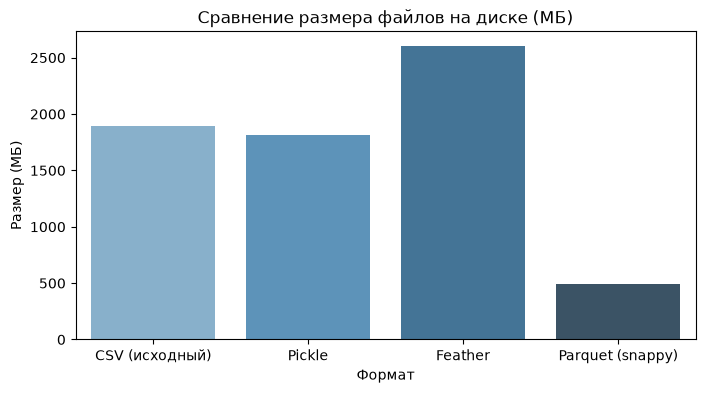

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

df_chart = df_table6[df_table6["Объём, МБ"] != "-"].copy()
df_chart["Объём, МБ"] = (
    df_chart["Объём, МБ"].str.replace(",", ".").astype(float)
)

plt.figure(figsize=(8, 4))
sns.barplot(data=df_chart, x="Формат", y="Объём, МБ", palette="Blues_d")
plt.title("Сравнение размера файлов на диске (МБ)", fontsize=12)
plt.ylabel("Размер (МБ)")
plt.show()